# 🚀 Proiect 1 - Predicția plecării clienților (Telco Customer Churn)

🗄️ 1. Explorarea datelor

📚 1.a) Se încarcă bibliotecile(libraries) și setul de date

Coloanele cele mai reprezentative
| Coloana | Explicație |
|---|---|
| tenure | De câte luni e clientul abonat |
| Contract | Tipul contractului: lunar, 1 an, 2 ani |
| MonthlyCharges | Cât plătește pe lună |
| TotalCharges | Cât a plătit în total până acum |
| Churn | Yes (=a plecat), No(=a rămas) |

In [2]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

url = "https://raw.githubusercontent.com/IBM/telco-customer-churn-on-icp4d/master/data/Telco-Customer-Churn.csv"
df = pd.read_csv(url)
df.head()

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


📏 1.b) Mărimea tabelului

In [3]:
print(f"Dimensiune (randuri, coloane): {df.shape}")
df.info()

Dimensiune (randuri, coloane): (7043, 21)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   object 
 1   gender            7043 non-null   object 
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   object 
 4   Dependents        7043 non-null   object 
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   object 
 7   MultipleLines     7043 non-null   object 
 8   InternetService   7043 non-null   object 
 9   OnlineSecurity    7043 non-null   object 
 10  OnlineBackup      7043 non-null   object 
 11  DeviceProtection  7043 non-null   object 
 12  TechSupport       7043 non-null   object 
 13  StreamingTV       7043 non-null   object 
 14  StreamingMovies   7043 non-null   object 
 15  Contract          7043 non-null   object 
 16  

⭕ 1.c) Valori lipsă (Transform TotalCharges în număr și verific dacă lipsesc valori)

In [4]:
df["TotalCharges"] = pd.to_numeric(df["TotalCharges"], errors="coerce")
print(df.isna().sum())

customerID           0
gender               0
SeniorCitizen        0
Partner              0
Dependents           0
tenure               0
PhoneService         0
MultipleLines        0
InternetService      0
OnlineSecurity       0
OnlineBackup         0
DeviceProtection     0
TechSupport          0
StreamingTV          0
StreamingMovies      0
Contract             0
PaperlessBilling     0
PaymentMethod        0
MonthlyCharges       0
TotalCharges        11
Churn                0
dtype: int64


📈 1.d) Mă uit câți clienți pleacă și câți rămân

In [5]:
print(df["Churn"].value_counts())
print(df["Churn"].value_counts(normalize=True))

Churn
No     5174
Yes    1869
Name: count, dtype: int64
Churn
No     0.73463
Yes    0.26537
Name: proportion, dtype: float64


Grafic 1: Câți pleacă vs câți rămân

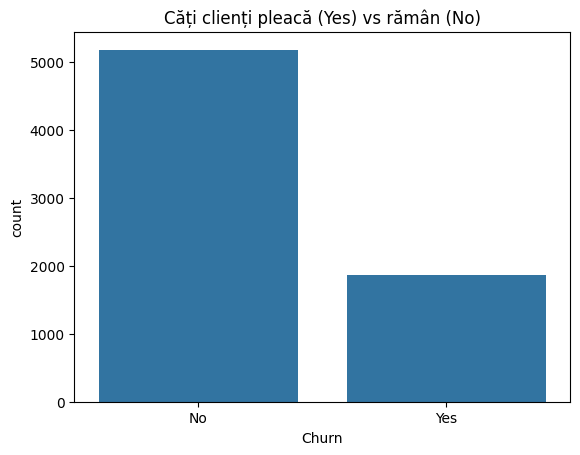

In [6]:
sns.countplot(data=df, x="Churn")
plt.title("Câți clienți pleacă (Yes) vs rămân (No)")
plt.show()

**👀Interpretare:**
Bara "No" este mai mare decât bara "Yes", adică din totalul de 7043 de clienți, 73.46% au rămas, iar 26.54% au renunțat la servicii. Asta înseamnă că datele sunt dezechilibrate. Un model care ar răspunde mereu "No" ar avea o acuratețe de ~73%, fără să învețe nimic, de aceea ne vom uita mai mult la recall pe clasa "Yes".

Grafic 2: Plecările după tipul contractului

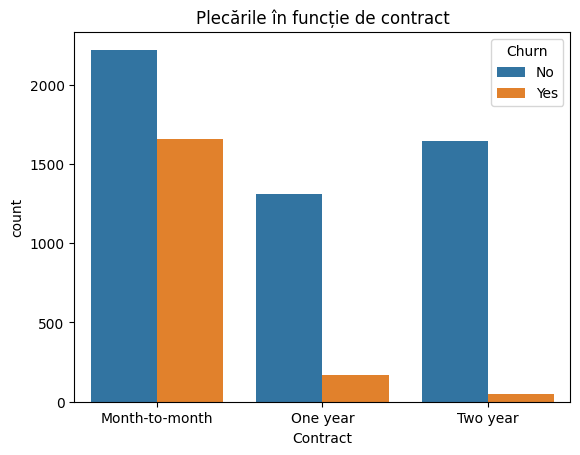

In [7]:
sns.countplot(data=df, x="Contract", hue="Churn")
plt.title("Plecările în funcție de contract")
plt.show()

**👀Interpretare:** La contractul "Month-to-month" pleacă mulți clienți ~43%, iar la contractele "One year" și "Two year" pleacă foarte puțini, ~3% la cel pe 2 ani. Deci, cu cât contractul este mai lung cu atât clienții pleaca mai rar.

Graficul 3: Vechimea clientului

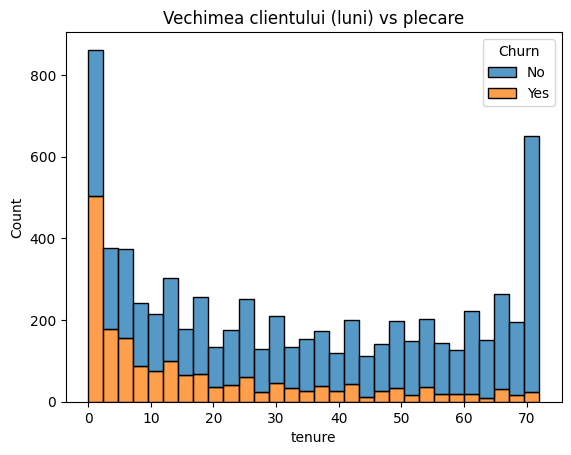

In [8]:
sns.histplot(data=df, x="tenure", hue="Churn", bins=30, multiple="stack")
plt.title("Vechimea clientului (luni) vs plecare")
plt.show()

**👀Interpretare:** Majoritatea plecărilor (portocaliu Yes) sunt la clienții noi (stânga) nu la cei vechi (dreapta).